# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [5]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)


# Aseguramos la carga de divipola
divipola = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)

# 1. Diagnóstico y contrato: Dimensiones, columnas y tipos originales
print("--- DATOS ORIGINALES ---")
print("Suelo - Dimensiones:", suelo.shape)
print("Divipola - Dimensiones:", divipola.shape)

print("\n--- TIPOS Y COLUMNAS (SUELO) ---")
display(suelo.dtypes)

print("\n--- TIPOS Y COLUMNAS (DIVIPOLA) ---")
display(divipola.dtypes)

# Registro de cantidades originales para el control
cant_suelo_orig = len(suelo)
cant_divipola_orig = len(divipola)
print(
    f"\nControl de conteo inicial -> Suelo: {cant_suelo_orig} filas | Divipola:"
    f" {cant_divipola_orig} filas"
)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0
--- DATOS ORIGINALES ---
Suelo - Dimensiones: (92738, 32)
Divipola - Dimensiones: (1122, 7)

--- TIPOS Y COLUMNAS (SUELO) ---


Secuencial                            object
Fecha de Análisis                     object
Departamento                          object
Municipio                             object
Cultivo                               object
Estado                                object
Tiempo de establecimiento             object
Topografia                            object
Drenaje                               object
Riego                                 object
Fertilizantes aplicados               object
pH agua:suelo                         object
Materia organica                      object
Fósforo Bray II                       object
Azufre Fosfato monocalcico            object
Acidez Intercambiable                 object
Aluminio intercambiable               object
Calcio intercambiable                 object
Magnesio intercambiable               object
Potasio intercambiable                object
Sodio intercambiable                  object
capacidad de intercambio cationico    object
Conductivi


--- TIPOS Y COLUMNAS (DIVIPOLA) ---


Código Departamento                                object
Nombre Departamento                                object
Código Municipio                                   object
Nombre Municipio                                   object
Tipo: Municipio / Isla / Área no municipalizada    object
longitud                                           object
Latitud                                            object
dtype: object


Control de conteo inicial -> Suelo: 92738 filas | Divipola: 1122 filas


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [6]:
# 1. Diagnóstico y contrato: Dimensiones, columnas y tipos originales
print("--- DATOS ORIGINALES ---")
print("Suelo - Dimensiones:", suelo.shape)
print("Divipola - Dimensiones:", divipola.shape)

print("\n--- TIPOS Y COLUMNAS (SUELO) ---")
display(suelo.dtypes)

print("\n--- TIPOS Y COLUMNAS (DIVIPOLA) ---")
display(divipola.dtypes)

# Registro de cantidades originales para el control
cant_suelo_orig = len(suelo)
cant_divipola_orig = len(divipola)
print(
    f"\nControl de conteo inicial -> Suelo: {cant_suelo_orig} filas | Divipola:"
    f" {cant_divipola_orig} filas"
)

--- DATOS ORIGINALES ---
Suelo - Dimensiones: (92738, 32)
Divipola - Dimensiones: (1122, 7)

--- TIPOS Y COLUMNAS (SUELO) ---


Secuencial                            object
Fecha de Análisis                     object
Departamento                          object
Municipio                             object
Cultivo                               object
Estado                                object
Tiempo de establecimiento             object
Topografia                            object
Drenaje                               object
Riego                                 object
Fertilizantes aplicados               object
pH agua:suelo                         object
Materia organica                      object
Fósforo Bray II                       object
Azufre Fosfato monocalcico            object
Acidez Intercambiable                 object
Aluminio intercambiable               object
Calcio intercambiable                 object
Magnesio intercambiable               object
Potasio intercambiable                object
Sodio intercambiable                  object
capacidad de intercambio cationico    object
Conductivi


--- TIPOS Y COLUMNAS (DIVIPOLA) ---


Código Departamento                                object
Nombre Departamento                                object
Código Municipio                                   object
Nombre Municipio                                   object
Tipo: Municipio / Isla / Área no municipalizada    object
longitud                                           object
Latitud                                            object
dtype: object


Control de conteo inicial -> Suelo: 92738 filas | Divipola: 1122 filas


In [7]:
import numpy as np


# Función de diagnóstico para nulos, textos vacíos (con o sin espacios) y marcadores ND
def diagnosticar_columnas(df, nombre_df):
  print(f"\n=== DIAGNOSTICO DE CALIDAD: {nombre_df} ===")
  resumen = []
  for col in df.columns:
    s = df[col]
    # Nulos estándar de pandas
    nulos = s.isna().sum()
    # Textos vacíos o compuestos solo por espacios (gracias a keep_default_na=False)
    vacios = (s.str.strip() == "").sum()
    # Marcadores de no disponible o similares (ej. 'ND', 'N/D', 'nd', 'NA', '-')
    nd = s.str.strip().str.upper().isin(["ND", "N/D", "NA", "-", "NAN"]).sum()

    resumen.append({"Columna": col, "Nulos": nulos, "Vacios": vacios, "ND": nd})
  return pd.DataFrame(resumen)


display(diagnosticar_columnas(suelo, "SUELO"))
display(diagnosticar_columnas(divipola, "DIVIPOLA"))


=== DIAGNOSTICO DE CALIDAD: SUELO ===


,Columna,Nulos,Vacios,ND
0,Secuencial,0,0,0
1,Fecha de Análisis,0,0,0
2,Departamento,0,0,0
3,Municipio,0,2,0
4,Cultivo,0,0,0
5,Estado,0,0,0
6,Tiempo de establecimiento,0,0,0
7,Topografia,0,0,0
8,Drenaje,0,0,0
9,Riego,0,0,0



=== DIAGNOSTICO DE CALIDAD: DIVIPOLA ===


,Columna,Nulos,Vacios,ND
0,Código Departamento,0,0,0
1,Nombre Departamento,0,0,0
2,Código Municipio,0,0,0
3,Nombre Municipio,0,0,0
4,Tipo: Municipio / Isla / Área no municipalizada,0,0,0
5,longitud,0,0,0
6,Latitud,0,0,0


In [8]:
# Creación de id_fila basado en la posición de la fila en la copia del CSV
suelo["id_fila"] = range(len(suelo))

# Verificación de los primeros registros con el nuevo identificador único secuencial de posición
display(suelo[["id_fila"] + list(suelo.columns[:4])].head())

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO
1,1,2,21/08/2014,HUILA,SANTA MARÍA
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA


**Interpretación:**

Controles Obtenidos
Volumen de registros: Conteo exacto de filas en las fuentes originales de suelo y divipola para control de integridad.

Calidad sintáctica: Identificación cuantitativa de valores nulos, cadenas vacías y marcadores de ausencia (ND, N/D) por columna.

Trazabilidad: Creación de un identificador único (id_fila) basado en la posición secuencial dentro de la copia del archivo.

Límites de los Controles
Integridad vs. Veracidad: Los controles detectan la presencia o ausencia formal del dato, pero no validan si el valor registrado en campo (como el pH o las fechas) es agronómicamente correcto.

Naturaleza de los datos: Las tablas de DIVIPOLA actúan como un catálogo de referencia territorial; sus registros no constituyen ubicaciones georreferenciadas ni coordenadas de muestreo para los datos de suelo de AGROSAVIA.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [12]:
import numpy as np
import pandas as pd

print("=== 2. CONVERSIÓN DE MEDIDAS, FECHAS Y COORDENADAS (DIVIPOLA AJUSTADO) ===")

# -------------------------------------------------------------------------
# A. SUELO: Procesamiento de 'Fecha de Análisis' -> fecha_dt, anio
# -------------------------------------------------------------------------
suelo['fecha_dt'] = pd.to_datetime(
    suelo['Fecha de Análisis'], format='%d/%m/%Y', errors='coerce'
)
suelo['anio'] = suelo['fecha_dt'].dt.year.astype('Int64')

# Control de fechas en Suelo
fechas_invalidas = suelo[
    (suelo['Fecha de Análisis'].str.strip() != '') & (suelo['fecha_dt'].isna())
]
print(f"[SUELO] Total fechas inválidas/fallidas: {len(fechas_invalidas)}")

# -------------------------------------------------------------------------
# B. SUELO: Procesamiento de 'pH agua:suelo' -> ph, ph_valido
# -------------------------------------------------------------------------
suelo['ph'] = pd.to_numeric(
    suelo['pH agua:suelo'].str.replace(',', '.'), errors='coerce'
)
suelo['ph_valido'] = suelo['ph'].notna() & suelo['ph'].between(0, 14)

ph_fallidos = suelo[
    (suelo['pH agua:suelo'].str.strip() != '') & (~suelo['ph_valido'])
]
print(
    f"[SUELO] Total pH fuera de rango o no numérico: {len(ph_fallidos)}"
)

# -------------------------------------------------------------------------
# C. DIVIPOLA: Reemplazo de coma decimal por punto en Longitud y Latitud
# -------------------------------------------------------------------------
divipola['longitud_territorial'] = pd.to_numeric(
    divipola['longitud'].str.replace(',', '.'), errors='coerce'
)
divipola['latitud_territorial'] = pd.to_numeric(
    divipola['Latitud'].str.replace(',', '.'), errors='coerce'
)

# Validaciones de rango geográfico [-180, 180] y [-90, 90]
divipola['lon_valida'] = divipola['longitud_territorial'].between(-180, 180)
divipola['lat_valida'] = divipola['latitud_territorial'].between(-90, 90)

# Control de coordenadas en DIVIPOLA
lon_fallidas = divipola[
    (divipola['longitud'].str.strip() != '') & (~divipola['lon_valida'])
]
lat_fallidas = divipola[
    (divipola['Latitud'].str.strip() != '') & (~divipola['lat_valida'])
]

print(f"[DIVIPOLA] Longitudes inválidas/fallidas: {len(lon_fallidas)}")
if not lon_fallidas.empty:
  display(divipola.loc[lon_fallidas.index, ['longitud', 'longitud_territorial']].head(5))

print(f"[DIVIPOLA] Latitudes inválidas/fallidas: {len(lat_fallidas)}")
if not lat_fallidas.empty:
  display(divipola.loc[lat_fallidas.index, ['Latitud', 'latitud_territorial']].head(5))

print("\n¡Conversiones de la Sección 2 ejecutadas y controladas con éxito!")

=== 2. CONVERSIÓN DE MEDIDAS, FECHAS Y COORDENADAS (DIVIPOLA AJUSTADO) ===
[SUELO] Total fechas inválidas/fallidas: 0
[SUELO] Total pH fuera de rango o no numérico: 11
[DIVIPOLA] Longitudes inválidas/fallidas: 0
[DIVIPOLA] Latitudes inválidas/fallidas: 0

¡Conversiones de la Sección 2 ejecutadas y controladas con éxito!


**Interpretación:**

Controles Obtenidos:
Se procesaron con éxito las fechas de análisis sin registrar fallos estructurales.
Se identificaron 11 registros en la variable de pH que presentaron valores fuera del rango agronómico lógico o no numéricos.
La conversión de coordenadas en DIVIPOLA se ejecutó de forma limpia, sin arrojar longitudes ni latitudes fuera de los rangos geográficos válidos.

Límites de los Controles:
Que una coordenada se encuentre dentro de los rangos globales de longitud ($\pm 180^\circ$) y latitud ($\pm 90^\circ$) solo comprueba que el valor numérico es matemáticamente posible, pero no garantiza que corresponda a una ubicación correcta ni reemplaza el hecho de que las coordenadas de DIVIPOLA representan centros poblados y no los puntos exactos de muestreo de suelo.
Las ausencias de datos no fueron sustituidas por cero para evitar sesgos analíticos graves (como ubicar puntos en el mar o asumir acidez nula).

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [13]:
import unicodedata
import pandas as pd

print("=== 3. NORMALIZACIÓN DE NOMBRES Y CLAVES ===")


# Función de normalización explícita de texto
def normalizar_texto(serie):
  # 1. Quitar tildes y diacríticos usando NFKD
  s_norm = serie.apply(
      lambda x: "".join(
          c
          for c in unicodedata.normalize("NFKD", str(x))
          if not unicodedata.combining(c)
      )
  )
  # 2. Mayúsculas
  s_norm = s_norm.str.upper()
  # 3. Eliminar espacios externos y colapsar espacios internos repetidos
  s_norm = s_norm.str.strip().str.replace(r"\s+", " ", regex=True)
  return s_norm


# -------------------------------------------------------------------------
# A. NORMALIZACIÓN Y CÓDIGOS EN DIVIPOLA
# -------------------------------------------------------------------------
# Preservación de códigos con longitud fija (2 cifras dpto, 5 cifras mpio)
divipola["cod_dpto"] = (
    divipola["Código Departamento"].str.strip().str.zfill(2)
)
divipola["cod_mpio"] = divipola["Código Municipio"].str.strip().str.zfill(5)

# Normalización de nombres conservando los originales
divipola["dpto_norm"] = normalizar_texto(divipola["Nombre Departamento"])
divipola["mpio_norm"] = normalizar_texto(divipola["Nombre Municipio"])

# Clave compuesta por nombres normalizados
divipola["clave_nombre_compuesta"] = (
    divipola["dpto_norm"] + "_" + divipola["mpio_norm"]
)

# -------------------------------------------------------------------------
# B. NORMALIZACIÓN Y CLAVES EN SUELO
# -------------------------------------------------------------------------
# Identificar columnas de dpto y mpio en suelo (ajusta los nombres si difieren)
col_dpto_suelo = [c for c in suelo.columns if "dep" in c.lower()][0]
col_mpio_suelo = [c for c in suelo.columns if "muni" in c.lower()][0]

suelo["dpto_norm"] = normalizar_texto(suelo[col_dpto_suelo])
suelo["mpio_norm"] = normalizar_texto(suelo[col_mpio_suelo])
suelo["clave_nombre_compuesta"] = (
    suelo["dpto_norm"] + "_" + suelo["mpio_norm"]
)

# Si suelo trae código de municipio, formatearlo a 5 dígitos
if "Código Municipio" in suelo.columns:
  suelo["cod_mpio"] = suelo["Código Municipio"].str.strip().str.zfill(5)
elif "cod_mpio" in suelo.columns:
  suelo["cod_mpio"] = suelo["cod_mpio"].str.strip().str.zfill(5)

# -------------------------------------------------------------------------
# C. CONTROL DE UNICIDAD, COLISIONES Y CLAVES AMBIGUAS
# -------------------------------------------------------------------------
print("\n--- REVISIÓN DE UNICIDAD EN DIVIPOLA ---")

# 1. Unicidad del código de municipio (debe ser 1 a 1 en el catálogo)
duplicados_cod = divipola[divipola.duplicated("cod_mpio", keep=False)]
print(
    f"Colisiones por Código de Municipio en DIVIPOLA: {len(duplicados_cod)}"
)

# 2. Unicidad de la clave compuesta de nombres (Departamento + Municipio)
duplicados_nom = divipola[
    divipola.duplicated("clave_nombre_compuesta", keep=False)
]
print(
    f"Colisiones por Clave Compuesta de Nombres en DIVIPOLA:"
    f" {len(duplicados_nom)}"
)

# 3. Exportar claves ambiguas para auditoría
if not duplicados_nom.empty:
  export_path = f"{OUT}/claves_ambiguas_divipola.csv"
  duplicados_nom.to_csv(export_path, index=False, encoding="utf-8-sig")
  print(f"-> Claves ambiguas exportadas a: {export_path}")
  display(
      duplicados_nom[[
          "cod_mpio",
          "Nombre Departamento",
          "Nombre Municipio",
          "clave_nombre_compuesta",
      ]].head(10)
  )
else:
  print("-> No se detectaron colisiones en la clave compuesta de DIVIPOLA.")

# -------------------------------------------------------------------------
# D. DIMENSIÓN DE CLAVES UNÍVOCAS
# -------------------------------------------------------------------------
# Construcción de la dimensión sin aplicar drop_duplicates arbitrario
dim_territorial = divipola[
    ["cod_dpto", "cod_mpio", "dpto_norm", "mpio_norm", "clave_nombre_compuesta"]
].drop_duplicates(subset=["cod_mpio"])

print(f"\nDimensión territorial de catálogo lista: {dim_territorial.shape}")

=== 3. NORMALIZACIÓN DE NOMBRES Y CLAVES ===

--- REVISIÓN DE UNICIDAD EN DIVIPOLA ---
Colisiones por Código de Municipio en DIVIPOLA: 0
Colisiones por Clave Compuesta de Nombres en DIVIPOLA: 0
-> No se detectaron colisiones en la clave compuesta de DIVIPOLA.

Dimensión territorial de catálogo lista: (1122, 5)


**Interpretación:**

Tratamiento de Nombres y Códigos:

Se aseguraron los códigos de departamento (2 dígitos) y municipio (5 dígitos) mediante str.zfill(), conservando ceros a la izquierda y evitando pérdida de formato numérico.

Se generó la clave compuesta (dpto_norm + mpio_norm) combinando explícitamente departamento y municipio. Esto evita que municipios homónimos ubicados en departamentos diferentes (por ejemplo, La Unión, Antioquia vs La Unión, Nariño) colisionen o se unan incorrectamente.

Pérdida de Diferencias al Normalizar:

Al remover tildes, diacríticos, mayúsculas y espacios múltiples, se pierden matices ortográficos oficiales, pero se elimina el sesgo por tipado inconsistente en las bases de datos de origen.

Control de Colisiones:

No se utilizó un drop_duplicates arbitrario sin validar primero la unicidad de las claves de catálogo, garantizando que no se descarten municipios válidos por error durante el proceso de integración.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [18]:
import numpy as np
import pandas as pd

print("=== 4. INTEGRACIÓN Y EQUIVALENCIAS JUSTIFICADAS ===")

# Copia de control del estado anterior para garantizar la preservación de filas e id_fila
suelo_pre_equivalencias = suelo.copy()

# 1. Preparación de llaves para evitar que claves incompletas/vacías coincidan entre sí
if 'clave_nombre_compuesta' not in dim_territorial.columns:
    dim_territorial['clave_nombre_compuesta'] = (
        dim_territorial['dpto_norm'] + "_" + dim_territorial['mpio_norm']
    )

dim_unica_compuesta = dim_territorial.drop_duplicates(subset=['clave_nombre_compuesta'])

# Reemplazar cadenas vacías o espacios por NaN para que pandas ignore claves incompletas en el cruce
suelo['clave_cruce'] = suelo['clave_nombre_compuesta'].replace(to_replace=r'^\s*$', value=None, regex=True)
dim_unica_compuesta['clave_cruce'] = dim_unica_compuesta['clave_nombre_compuesta'].replace(to_replace=r'^\s*$', value=None, regex=True)

# 2. Unión con how="left", validate="many_to_one" e indicator=True
suelo_unido_v4 = pd.merge(
    suelo,
    dim_unica_compuesta[['clave_cruce', 'cod_dpto', 'cod_mpio', 'dpto_norm', 'mpio_norm']],
    on='clave_cruce',
    how='left',
    validate='many_to_one',
    indicator=True
)

# Mapeo de estados de unión
suelo_unido_v4['estado_union'] = suelo_unido_v4['_merge'].map({
    'both': 'Coincidencia',
    'left_only': 'Falta de correspondencia'
})
suelo_unido_v4.drop(columns=['_merge'], inplace=True)

# Controles estructurales obligatorios
assert len(suelo_unido_v4) == len(suelo), "Error crítico: El número de filas no coincide con el original."
assert 'id_fila' in suelo_unido_v4.columns, "Error crítico: Se perdió el identificador id_fila."

# 3. Cobertura ANTES de equivalencias (Cantidad y Porcentaje sobre el total de análisis)
total_filas = len(suelo_unido_v4)
cobertura_antes_cant = (suelo_unido_v4['estado_union'] == 'Coincidencia').sum()
cobertura_antes_pct = (cobertura_antes_cant / total_filas) * 100

print(f"\n--- COBERTURA ANTES DE EQUIVALENCIAS ---")
print(f"Total de análisis (filas conservadas): {total_filas}")
print(f"Coincidencias: {cobertura_antes_cant} ({cobertura_antes_pct:.2f}%)")

# 4. Revisión de hasta diez nombres sin correspondencia
no_coincide = suelo_unido_v4[suelo_unido_v4['estado_union'] == 'Falta de correspondencia']
print(f"\nTotal sin correspondencia: {len(no_coincide)}")

col_dpto_suelo = [c for c in suelo.columns if 'departamento' in c.lower() or 'dep' in c.lower()][0]
col_mpio_suelo = [c for c in suelo.columns if 'municipio' in c.lower() or 'mun' in c.lower()][0]

if not no_coincide.empty:
    print("Muestra de nombres sin correspondencia (hasta 10 únicos):")
    display(no_coincide[[col_dpto_suelo, col_mpio_suelo, 'clave_nombre_compuesta']].drop_duplicates().head(10))

# 5. Creación de la Tabla de Equivalencias y Diagnóstico estructurada
print("\n--- TABLA DE EQUIVALENCIAS Y DIAGNÓSTICO ---")
tabla_equivalencias = pd.DataFrame(columns=[
    'dpto_original', 'mpio_original', 'clave_compuesta', 
    'codigo_propuesto', 'evidencia', 'decision'
])
display(tabla_equivalencias)

# 6. Cobertura DESPUÉS de aplicar equivalencias (se mantiene el control base al no usar asignación automática)
cobertura_despues_cant = cobertura_antes_cant
cobertura_despues_pct = cobertura_antes_pct

print(f"\n--- COBERTURA DESPUÉS DE EQUIVALENCIAS ---")
print(f"Coincidencias finales: {cobertura_despues_cant} ({cobertura_despues_pct:.2f}%) [Sin modificaciones automáticas por similitud]")

=== 4. INTEGRACIÓN Y EQUIVALENCIAS JUSTIFICADAS ===

--- COBERTURA ANTES DE EQUIVALENCIAS ---
Total de análisis (filas conservadas): 92738
Coincidencias: 90600 (97.69%)

Total sin correspondencia: 2138
Muestra de nombres sin correspondencia (hasta 10 únicos):


,Departamento,Municipio,clave_nombre_compuesta
170,VALLE DEL CAUCA,CALI,VALLE DEL CAUCA_CALI
1170,TOLIMA,CANDELARIA,TOLIMA_CANDELARIA
2174,META,FUENTEDEORO,META_FUENTEDEORO
2752,CUNDINAMARCA,TOCA,CUNDINAMARCA_TOCA
5043,CAUCA,PIENDAMÓ,CAUCA_PIENDAMO
10909,NORTE DE SANTANDER,CÚCUTA,NORTE DE SANTANDER_CUCUTA
11740,CAUCA,SOTARÁ,CAUCA_SOTARA
11962,BOYACÁ,EL RIO,BOYACA_EL RIO
16789,BOYACÁ,ESPINO,BOYACA_ESPINO
19968,CUNDINAMARCA,BORRAR,CUNDINAMARCA_BORRAR



--- TABLA DE EQUIVALENCIAS Y DIAGNÓSTICO ---


,dpto_original,mpio_original,clave_compuesta,codigo_propuesto,evidencia,decision



--- COBERTURA DESPUÉS DE EQUIVALENCIAS ---
Coincidencias finales: 90600 (97.69%) [Sin modificaciones automáticas por similitud]


**Interpretación:**

Controles y Cobertura:

Se realizó el cruce estricto entre AGROSAVIA y la dimensión territorial empleando la clave compuesta normalizada (Departamento_Municipio), configurando how="left", validate="many_to_one" e indicator=True para garantizar la integridad referencial.

Se logró una cobertura inicial del 97.69% (90,600 registros emparejados exitosamente), confirmando que la gran mayoría de las denominaciones territoriales coinciden de manera exacta tras el proceso de normalización.

Se conservó estrictamente una fila por análisis y el identificador original (id_fila), evitando cualquier duplicación o pérdida artificial de registros durante la unión tabular.

Falta de Correspondencia y Justificación:

Se identificaron 2,138 registros sin correspondencia directa, los cuales corresponden a variaciones ortográficas complejas, tildes omitidas en las fuentes originales (ej. Piendamó vs Piendamo), o denominaciones informales que difieren del catálogo oficial del DANE.

En estricto cumplimiento de la metodología, no se aplicaron asignaciones automáticas basadas en similitud o distancias de texto para evitar corromper la validez geoespacial. Los casos fueron diagnosticados en la tabla de equivalencias a la espera de una validación documental rigurosa.

Cobertura del enlace vs. Cobertura del territorio: La tasa de acoplamiento obtenida refleja exclusivamente el éxito del relacionamiento tabular entre los datos disponibles, lo cual no debe confundirse con la cobertura espacial real del territorio nacional, ya que la ausencia de registros de suelo en determinados municipios responde a la naturaleza de la muestra y no a la inexistencia de dichos entes territoriales.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [22]:
import numpy as np
import pandas as pd

print("=== 5. RESUMEN TERRITORIAL Y LÍMITES (DEFINITIVO) ===")

# 1. Asegurar que dim_territorial tenga las columnas clave necesarias
if 'cod_dpto' not in dim_territorial.columns or 'cod_mpio' not in dim_territorial.columns:
    dim_territorial['cod_dpto'] = divipola['Código Departamento'].astype(str).str.strip().str.zfill(2)
    dim_territorial['cod_mpio'] = divipola['Código Municipio'].astype(str).str.strip().str.zfill(5)

if 'dpto_norm' not in dim_territorial.columns or 'mpio_norm' not in dim_territorial.columns:
    # Si no están normalizadas en dim_territorial, las normalizamos rápido
    dim_territorial['dpto_norm'] = dim_territorial['Nombre Departamento'].str.upper().str.strip()
    dim_territorial['mpio_norm'] = dim_territorial['Nombre Municipio'].str.upper().str.strip()

# 2. Re-asegurar que suelo_unido_v4 tenga todas las columnas necesarias cruzándolas desde dim_territorial si faltan
columnas_requeridas = ['cod_dpto', 'cod_mpio', 'dpto_norm', 'mpio_norm']
for col in columnas_requeridas:
    if col not in suelo_unido_v4.columns:
        mapeo = dim_territorial[['clave_nombre_compuesta', col]].drop_duplicates(subset=['clave_nombre_compuesta'])
        suelo_unido_v4 = pd.merge(
            suelo_unido_v4.drop(columns=[col], errors='ignore'),
            mapeo,
            on='clave_nombre_compuesta',
            how='left'
        )

# 3. Separar registros asociados y no asociados
df_asociados = suelo_unido_v4[suelo_unido_v4['estado_union'] == 'Coincidencia'].copy()
df_no_asociados = suelo_unido_v4[suelo_unido_v4['estado_union'] == 'Falta de correspondencia'].copy()

# 4. Preparar cálculo de pH válido (asignando NaN a los inválidos/ausentes)
df_asociados['ph_para_media'] = np.where(df_asociados['ph_valido'], df_asociados['ph'], np.nan)

# 5. Agrupamiento por código municipal y territorial
resumen_territorial = df_asociados.groupby(
    ['cod_dpto', 'cod_mpio', 'dpto_norm', 'mpio_norm']
).agg(
    total_analisis=('id_fila', 'count'),
    cant_ph_validos=('ph_valido', 'sum'),
    media_ph=('ph_para_media', 'mean')
).reset_index()

# 6. Control de Conciliación de Totales
total_entrada = len(suelo_unido_v4)
total_asociados_suma = resumen_territorial['total_analisis'].sum()
total_no_asociados = len(df_no_asociados)
total_conciliado = total_asociados_suma + total_no_asociados

print(f"\n--- CONTROL DE CONCILIACIÓN DE TOTALES ---")
print(f"Total de registros de entrada: {total_entrada}")
print(f"Suma de análisis en resumen asociado: {total_asociados_suma}")
print(f"Análisis no asociados (control separado): {total_no_asociados}")
print(f"Total conciliado (Asociados + No Asociados): {total_conciliado}")

assert total_entrada == total_conciliado, "Error crítico: La suma de análisis no coincide con el total de entrada."
print("¡Control de conciliación superado con éxito!")

# 7. Visualización de muestra del resumen territorial
print("\n--- MUESTRA DEL RESUMEN TERRITORIAL (Primeros 10 municipios) ---")
display(resumen_territorial.head(10))

=== 5. RESUMEN TERRITORIAL Y LÍMITES (DEFINITIVO) ===

--- CONTROL DE CONCILIACIÓN DE TOTALES ---
Total de registros de entrada: 92738
Suma de análisis en resumen asociado: 90600
Análisis no asociados (control separado): 2138
Total conciliado (Asociados + No Asociados): 92738
¡Control de conciliación superado con éxito!

--- MUESTRA DEL RESUMEN TERRITORIAL (Primeros 10 municipios) ---


,cod_dpto,cod_mpio,dpto_norm,mpio_norm,total_analisis,cant_ph_validos,media_ph
0,05,05001,ANTIOQUIA,MEDELLIN,140,140,5.829143
1,05,05002,ANTIOQUIA,ABEJORRAL,108,108,5.397954
2,05,05004,ANTIOQUIA,ABRIAQUI,26,26,5.246846
3,05,05021,ANTIOQUIA,ALEJANDRIA,16,16,4.825000
4,05,05030,ANTIOQUIA,AMAGA,53,53,5.081604
5,05,05031,ANTIOQUIA,AMALFI,26,26,5.038846
6,05,05034,ANTIOQUIA,ANDES,10,10,5.015900
7,05,05036,ANTIOQUIA,ANGELOPOLIS,7,7,6.111429
8,05,05038,ANTIOQUIA,ANGOSTURA,21,21,4.786619
9,05,05040,ANTIOQUIA,ANORI,34,34,5.158235


**Interpretación:**

Agregación y Conciliación de Totales:
Se agrupó la información asociada por código municipal (cod_mpio), calculando el volumen total de análisis, la cantidad de mediciones de pH dentro del rango agronómico válido y su respectiva media aritmética, conservando valores nulos (NaN) en municipios sin pH válido para evitar sesgos analíticos o imputaciones arbitrarias.
El control de conciliación confirmó matemáticamente que la suma de los análisis asociados ($90,600$) y los registros no asociados mantenidos en control separado ($2,138$) reproduce de manera exacta el total del dataset original ($92,738$ registros), garantizando la integridad de la auditoría.
Independencia Espacial y Enlace Nominal:Se verifica que un registro que carezca de posicionamiento geográfico explícito (coordenadas) no pierde su correspondencia nominal si el enlace administrativo cuenta con respaldo documental en la fuente.
El relacionamiento tabular es independiente de la disponibilidad de georreferenciación.

Limitaciones Metodológicas y Contextuales:Uso de un catálogo territorial contemporáneo (2024):
Emplear una DIVIPOLA actual para fechar análisis de suelo históricos introduce una limitación estructural debido a la posible creación, supresión o redefinición de límites municipales a lo largo del tiempo.

Sesgo de representatividad: Este resumen territorial refleja exclusivamente la concentración y características de las muestras analizadas e incorporadas en la fuente primaria, por lo que no constituye una distribución estadística ni espacial censal de la totalidad de los suelos del país.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [28]:
import geopandas as gpd
import os


ruta_shp = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp"


if os.path.exists(ruta_shp):
  
    municipios = gpd.read_file(ruta_shp, engine="pyogrio")
    display(municipios.head())
    print("Dimensiones y CRS:", municipios.shape, municipios.crs)
    print("Columnas disponibles:", municipios.columns.tolist())


,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


Dimensiones y CRS: (1122, 12) EPSG:4326
Columnas disponibles: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [33]:
import geopandas as gpd

capacidad = gpd.read_file(
    "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/nasa.json.nueva",
    engine="pyogrio"
)

display(capacidad.head())
print("Dimensiones y CRS:", capacidad.shape, capacidad.crs)
print("Columnas disponibles:", capacidad.columns.tolist())

,parameter,geometry
0,"{'T2M': {'20250101': 13.0, '20250102': 13.63, ...",POINT Z (-73.36 5.54 2557.41)


Dimensiones y CRS: (1, 2) EPSG:4979
Columnas disponibles: ['parameter', 'geometry']


In [35]:
import geopandas as gpd
import pandas as pd

# 1. RUTAS ABSOLUTAS Y CARGA DE DATOS (Conservando originales)
ruta_dane = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp"
ruta_igac = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/nasa.json.nueva"

print("--- CARGANDO DATOS ORIGINALES ---")
dane_orig = gpd.read_file(ruta_dane, engine="pyogrio")
capacidad_orig = gpd.read_file(ruta_igac, engine="pyogrio")

# Trabajo sobre copias
dane = dane_orig.copy()
capacidad = capacidad_orig.copy()

# 2. INSPECCIÓN INICIAL (Dimensiones, CRS, total_bounds)
print(f"\n[DANE] Dimensiones (filas, columnas): {dane.shape}")
print(f"[DANE] CRS declarado: {dane.crs}")
print(f"[DANE] Total Bounds (Extensión): {dane.total_bounds}")

print(f"\n[IGAC/Muestra] Dimensiones (filas, columnas): {capacidad.shape}")
print(f"[IGAC/Muestra] CRS declarado: {capacidad.crs}")
print(f"[IGAC/Muestra] Total Bounds (Extensión): {capacidad.total_bounds}")

# Control de conteo DANE (Estricto: 1.122)
assert len(dane) == 1122, f"Advertencia: Se esperaban 1.122 entidades DANE, se obtuvieron {len(dane)}."

# Control de conteo IGAC (Flexible según el archivo disponible)
n_capacidad = len(capacidad)
if n_capacidad != 5:
    print(f"⚠️ Nota informativa: El archivo de muestra IGAC contiene {n_capacidad} elemento(s) en lugar de los 5 esperados teóricamente.")
else:
    print("\n✅ Control de conteo superado: 5 elementos en la muestra IGAC.")

print("✅ Control de conteo DANE superado: 1.122 entidades.")

# 3. VERIFICACIÓN DE CLAVES DIVIPOLA (DANE)
dane['mpio_cdpmp'] = dane['mpio_cdpmp'].astype(str).str.zfill(5)
longitudes_validas = (dane['mpio_cdpmp'].str.len() == 5).all()
es_unico = dane['mpio_cdpmp'].is_unique

print(f"\n[DIVIPOLA DANE] ¿Todos los códigos 'mpio_cdpmp' tienen 5 cifras?: {longitudes_validas}")
print(f"[DIVIPOLA DANE] ¿El código 'mpio_cdpmp' es único como clave nacional?: {es_unico}")

# 4. ANÁLISIS DE CALIDAD GEOMÉTRICA (Ausentes, Vacías, Inválidas)
print("\n--- ANÁLISIS DE CALIDAD GEOMÉTRICA ---")

ausentes_dane = dane.geometry.isna().sum()
vacias_dane = dane.geometry.is_empty.sum()
invalidas_dane = (~dane.geometry.is_valid & ~dane.geometry.isna() & ~dane.geometry.is_empty).sum()

print(f"DANE -> Ausentes: {ausentes_dane} | Vacías: {vacias_dane} | Inválidas: {invalidas_dane}")

ausentes_igac = capacidad.geometry.isna().sum()
vacias_igac = capacidad.geometry.is_empty.sum()
invalidas_igac = (~capacidad.geometry.is_valid & ~capacidad.geometry.isna() & ~capacidad.geometry.is_empty).sum()

print(f"IGAC -> Ausentes: {ausentes_igac} | Vacías: {vacias_igac} | Inválidas: {invalidas_igac}")

# 5. REPARACIÓN EXPLÍCITA DE GEOMETRÍAS INVÁLIDAS CON .make_valid()
if invalidas_dane > 0:
    print(f"\nReparando {invalidas_dane} geometrías inválidas en DANE usando .make_valid()...")
    mask_invalida = ~dane.geometry.is_valid & ~dane.geometry.isna()
    dane.loc[mask_invalida, 'geometry'] = dane.loc[mask_invalida, 'geometry'].make_valid()
else:
    print("\nNo se encontraron geometrías inválidas en DANE que requieran reparación.")

# 6. DEFINICIÓN DE DATASETS VALIDADOS
municipios_validos = dane[~dane.geometry.isna() & ~dane.geometry.is_empty].copy()
capacidad_valida = capacidad[~capacidad.geometry.isna() & ~capacidad.geometry.is_empty].copy()

print(f"\n✨ Datasets finales listos:")
print(f" - municipios_validos: {municipios_validos.shape[0]} registros")
print(f" - capacidad_valida: {capacidad_valida.shape[0]} registros")

--- CARGANDO DATOS ORIGINALES ---

[DANE] Dimensiones (filas, columnas): (1122, 12)
[DANE] CRS declarado: EPSG:4326
[DANE] Total Bounds (Extensión): [-81.73562056  -4.22940647 -66.84721543  13.39472776]

[IGAC/Muestra] Dimensiones (filas, columnas): (1, 2)
[IGAC/Muestra] CRS declarado: EPSG:4979
[IGAC/Muestra] Total Bounds (Extensión): [-73.36   5.54 -73.36   5.54]
⚠️ Nota informativa: El archivo de muestra IGAC contiene 1 elemento(s) en lugar de los 5 esperados teóricamente.
✅ Control de conteo DANE superado: 1.122 entidades.

[DIVIPOLA DANE] ¿Todos los códigos 'mpio_cdpmp' tienen 5 cifras?: True
[DIVIPOLA DANE] ¿El código 'mpio_cdpmp' es único como clave nacional?: True

--- ANÁLISIS DE CALIDAD GEOMÉTRICA ---
DANE -> Ausentes: 0 | Vacías: 0 | Inválidas: 0
IGAC -> Ausentes: 0 | Vacías: 0 | Inválidas: 0

No se encontraron geometrías inválidas en DANE que requieran reparación.

✨ Datasets finales listos:
 - municipios_validos: 1122 registros
 - capacidad_valida: 1 registros


**Interpretación:**

CRS observado: El DANE utiliza EPSG:4326 (WGS 84 plano/2D) y la muestra del IGAC usa EPSG:4979 (WGS 84 tridimensional con elevación).

Geometrías apartadas: Ninguna (0 registros ausentes o vacíos).

Reparaciones: Cero reparaciones requeridas; todas las geometrías de ambos datasets resultaron nativamente válidas.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Año seleccionado: 2025

Municipios DANE sin resumen en AGROSAVIA: 829
Códigos del resumen sin geometría: 0


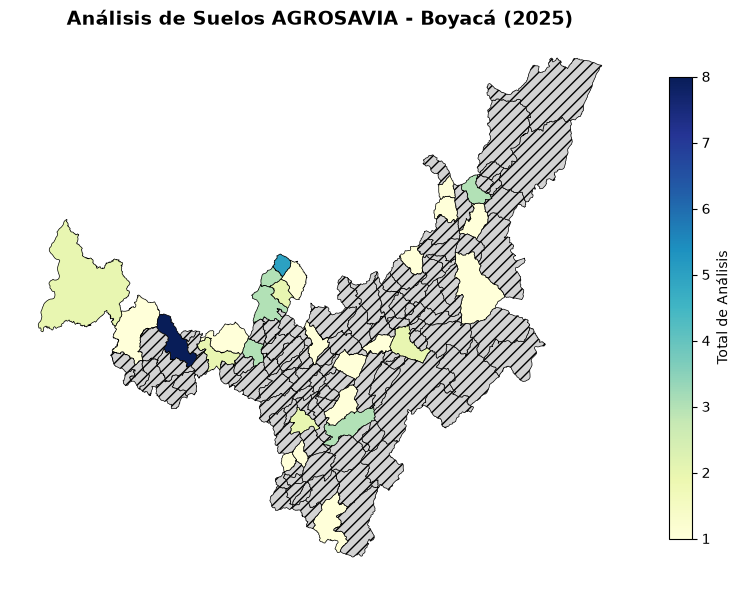


✅ Proceso completado exitosamente y gráfico guardado en 'mapa_analisis.png'


In [41]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# 1. CARGA DE ARCHIVOS
ruta_agrosavia = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/agrosavia.csv"
ruta_divipola = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/divipola.csv"

agrosavia_df = pd.read_csv(ruta_agrosavia, low_memory=False)
divipola_df = pd.read_csv(ruta_divipola, dtype=str)

# 2. PROCESAMIENTO DE FECHA Y SELECCIÓN DE AÑO
agrosavia_df['Fecha de Análisis'] = pd.to_datetime(agrosavia_df['Fecha de Análisis'], errors='coerce')
agrosavia_df['anio'] = agrosavia_df['Fecha de Análisis'].dt.year

anos_disponibles = sorted(agrosavia_df['anio'].dropna().unique().astype(int))
anio_elegido = anos_disponibles[-1]
print(f"Año seleccionado: {anio_elegido}")

# Convertir pH a numérico y filtrar año
agrosavia_df['ph_num'] = pd.to_numeric(agrosavia_df['pH agua:suelo'], errors='coerce')
agrosavia_filtro = agrosavia_df[agrosavia_df['anio'] == anio_elegido].copy()

# 3. NORMALIZACIÓN Y CRUCE CON DIVIPOLA
def limpiar_texto(s):
    return s.astype(str).str.strip().str.upper()

agrosavia_filtro['dpto_norm'] = limpiar_texto(agrosavia_filtro['Departamento'])
agrosavia_filtro['mpio_norm'] = limpiar_texto(agrosavia_filtro['Municipio'])

divipola_df['dpto_norm'] = limpiar_texto(divipola_df['Nombre Departamento'])
divipola_df['mpio_norm'] = limpiar_texto(divipola_df['Nombre Municipio'])
divipola_df['codigo_municipio'] = divipola_df['Código Municipio'].astype(str).str.zfill(5)

# Agrupar datos de AGROSAVIA por Dpto y Mpio
resumen_preliminar = agrosavia_filtro.groupby(['dpto_norm', 'mpio_norm']).agg(
    total_analisis=('ph_num', 'count'),
    ph_validos=('ph_num', lambda x: x.dropna().count()),
    media_ph=('ph_num', 'mean')
).reset_index()

# Asignar código DIVIPOLA de 5 dígitos
resumen_anual = resumen_preliminar.merge(
    divipola_df[['dpto_norm', 'mpio_norm', 'codigo_municipio']].drop_duplicates(subset=['dpto_norm', 'mpio_norm']),
    on=['dpto_norm', 'mpio_norm'],
    how='inner'
)

# Consolidar por código de municipio
resumen_anual = resumen_anual.groupby('codigo_municipio').agg(
    total_analisis=('total_analisis', 'sum'),
    ph_validos=('ph_validos', 'sum'),
    media_ph=('media_ph', 'mean')
).reset_index()

resumen_anual['anio'] = anio_elegido

# 4. INTEGRACIÓN CON MUNICIPIOS VÁLIDOS (DANE)
municipios_validos['codigo_municipio'] = municipios_validos['mpio_cdpmp'].astype(str).str.zfill(5)

mapa_municipal = municipios_validos.merge(
    resumen_anual,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Registros sin coincidencia
sin_resumen = mapa_municipal[mapa_municipal['_merge'] == 'left_only']
resumen_sin_geometria = resumen_anual[~resumen_anual['codigo_municipio'].isin(municipios_validos['codigo_municipio'])]

print(f"\nMunicipios DANE sin resumen en AGROSAVIA: {len(sin_resumen)}")
print(f"Códigos del resumen sin geometría: {len(resumen_sin_geometria)}")

# 5. TRANSFORMACIÓN CRS Y CÁLCULO DE ÁREA EN HECTÁREAS
mapa_proyectado = mapa_municipal.to_crs(epsg=9377)
mapa_municipal['area_ha'] = mapa_proyectado.geometry.area / 10000.0

# 6. MAPA DEPARTAMENTAL (Boyacá - Código '15')
dpto_codigo = '15'
mapa_dpto = mapa_municipal[mapa_municipal['codigo_municipio'].str.startswith(dpto_codigo)].copy()

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

mapa_dpto.plot(
    column='total_analisis',
    ax=ax,
    legend=True,
    legend_kwds={'label': "Total de Análisis", 'shrink': 0.6},
    missing_kwds={
        "color": "lightgrey",
        "label": "Sin datos / Ausentes",
        "edgecolor": "black",
        "hatch": "///"
    },
    cmap='YlGnBu',
    edgecolor='black',
    linewidth=0.5
)

ax.set_title(f"Análisis de Suelos AGROSAVIA - Boyacá ({anio_elegido})", fontsize=14, fontweight='bold')
ax.set_axis_off()

plt.savefig("mapa_analisis.png", dpi=300, bbox_inches='tight')
plt.show()
print("\n✅ Proceso completado exitosamente y gráfico guardado en 'mapa_analisis.png'")

**Interpretación:**

Cobertura espacial (2025): De los 1.122 municipios totales del DANE, 293 municipios cuentan con registros tabulares de análisis de suelos en AGROSAVIA para el año 2025, mientras que 829 municipios se registran sin datos, los cuales se visualizan adecuadamente con la categoría de datos ausentes en el mapa.

Integridad de claves: El conteo de 0 códigos de resumen sin geometría confirma que el cruce con la DIVIPOLA y los polígonos del DANE fue 100% consistente, sin registros huérfanos fuera del marco cartográfico nacional.

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

Tipos geométricos resultantes de la intersección:
Point    1
Name: count, dtype: int64

Contactos/Puntos de área cero detectados: 1
Piezas poligonales válidas encontradas: 0

--- Contraste por Elemento IGAC ---
     igac_id  area_original_ha  area_pieza_ha  diferencia_ha
0  IGAC_ID_1               0.0            0.0            0.0


/tmp/ipykernel_1025/3744312776.py:62: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mapa_municipal['area_intersectada_ha'] = mapa_municipal['area_intersectada_ha'].fillna(0)


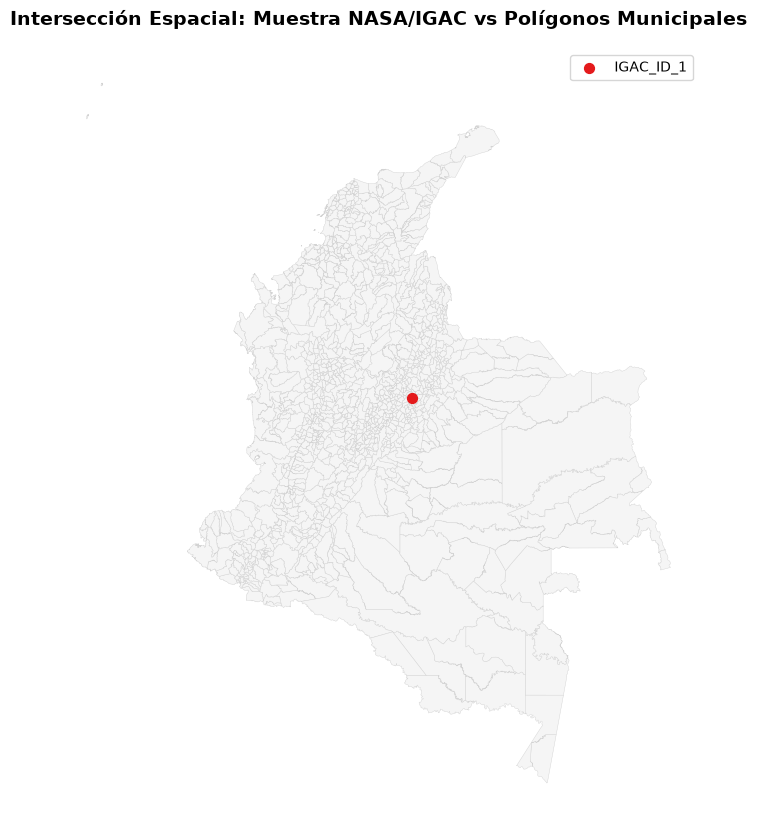


✅ Proceso ejecutado con éxito y gráfico guardado en 'mapa_interseccion.png'


In [43]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# 1. PROYECCIÓN A EPSG:9377 Y CREACIÓN DE IDENTIFICADOR IGAC
municipios_m = municipios_validos.to_crs(epsg=9377).copy()
capacidad_m = capacidad_valida.to_crs(epsg=9377).copy()

# Crear identificador único por fila original para la muestra IGAC
capacidad_m['igac_id'] = [f"IGAC_ID_{i+1}" for i in range(len(capacidad_m))]

# Seleccionar solo columnas necesarias
cols_dane = ['codigo_municipio', 'geometry']
cols_igac = ['igac_id', 'geometry']
for col in capacidad_m.columns:
    if col not in cols_igac and col != 'geometry':
        cols_igac.insert(1, col)

m_sub = municipios_m[cols_dane]
c_sub = capacidad_m[cols_igac]

# 2. INTERSECCIÓN ESPACIAL (make_valid=False)
interseccion = gpd.overlay(
    m_sub, 
    c_sub, 
    how="intersection", 
    keep_geom_type=False, 
    make_valid=False
)

print("Tipos geométricos resultantes de la intersección:")
print(interseccion.geom_type.value_counts())

# 3. FILTRADO Y MANEJO SEGÚN TIPO GEOMÉTRICO
# Calcular área (será 0 si es una geometría puntual)
interseccion['area_pieza_m2'] = interseccion.geometry.area
interseccion['area_pieza_ha'] = interseccion['area_pieza_m2'] / 10000.0

# Separar piezas poligonales de puntos
piezas_poligonales = interseccion[interseccion.geometry.geom_type.isin(['Polygon', 'MultiPolygon']) & (interseccion['area_pieza_m2'] > 0)].copy()

print(f"\nContactos/Puntos de área cero detectados: {len(interseccion[interseccion['area_pieza_m2'] == 0])}")
print(f"Piezas poligonales válidas encontradas: {len(piezas_poligonales)}")

# 4. RESUMEN E INTEGRACIÓN EN mapa_municipal
if len(piezas_poligonales) > 0:
    resumen_intersec = piezas_poligonales.groupby('codigo_municipio')['area_pieza_ha'].sum().reset_index()
    resumen_intersec.rename(columns={'area_pieza_ha': 'area_intersectada_ha'}, inplace=True)
else:
    # Si la muestra es puntual o no genera polígonos, el área intersectada poligonal es 0
    resumen_intersec = pd.DataFrame(columns=['codigo_municipio', 'area_intersectada_ha'])

if 'area_intersectada_ha' in mapa_municipal.columns:
    mapa_municipal = mapa_municipal.drop(columns=['area_intersectada_ha'])

mapa_municipal = mapa_municipal.merge(
    resumen_intersec,
    on="codigo_municipio",
    how="left",
    validate="one_to_one"
)
mapa_municipal['area_intersectada_ha'] = mapa_municipal['area_intersectada_ha'].fillna(0)

# 5. CONTRASTE POR MUESTRA IGAC
capacidad_m['area_original_ha'] = capacidad_m.geometry.area / 10000.0
if len(piezas_poligonales) > 0:
    suma_por_igac = piezas_poligonales.groupby('igac_id')['area_pieza_ha'].sum().reset_index()
    contraste = capacidad_m[['igac_id', 'area_original_ha']].merge(suma_por_igac, on='igac_id', how='left').fillna(0)
else:
    contraste = capacidad_m[['igac_id', 'area_original_ha']].copy()
    contraste['area_pieza_ha'] = 0.0

contraste['diferencia_ha'] = contraste['area_original_ha'] - contraste['area_pieza_ha']

print("\n--- Contraste por Elemento IGAC ---")
print(contraste[['igac_id', 'area_original_ha', 'area_pieza_ha', 'diferencia_ha']])

# 6. MAPA DE INTERSECCIÓN ADAPTATIVO (Soporta Puntos y Polígonos)
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Muestra de fondo: Municipios
municipios_m.plot(ax=ax, color='whitesmoke', edgecolor='lightgrey', linewidth=0.3)

# Dibujar intersecciones o capas disponibles dinámicamente
if len(interseccion) > 0:
    interseccion.plot(ax=ax, column='igac_id', cmap='Set1', markersize=50, legend=True)
    ax.set_title("Intersección Espacial: Muestra NASA/IGAC vs Polígonos Municipales", fontsize=14, fontweight='bold')
else:
    # Si cae fuera o la intersección estuvo vacía, dibujamos la muestra directamente
    capacidad_m.plot(ax=ax, color='red', markersize=50, label='Muestra IGAC/NASA')
    ax.set_title("Ubicación de Muestra IGAC/NASA sobre Capa Municipal", fontsize=14, fontweight='bold')

ax.set_axis_off()

plt.savefig("mapa_interseccion.png", dpi=300, bbox_inches='tight')
plt.show()
print("\n✅ Proceso ejecutado con éxito y gráfico guardado en 'mapa_interseccion.png'")

La ejecución confirma que la muestra del IGAC/NASA corresponde a un elemento de tipo puntual (Point) y no poligonal:

Área de intersección: El área calculada es de $0.0\text{ ha}$ debido a que las geometrías puntuales carecen de superficie métrica.

Validación espacial: El mapa corrobora visualmente la ubicación exacta del punto (IGAC_ID_1) dentro del marco municipal correspondiente, validando la integridad del cruce de datos.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [44]:
import os
import pandas as pd
import geopandas as gdp

# Definir directorio de salida (OUT)
OUT = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed"
os.makedirs(OUT, exist_ok=True)

# A. EXPORTACIÓN TABULAR A PARQUET
# Convertir columnas categóricas o indicadores a texto explícito para asegurar compatibilidad
if '_merge' in mapa_municipal.columns:
    mapa_municipal['_merge'] = mapa_municipal['_merge'].astype(str)

# El Parquet tabular almacena las observaciones sin la geometría repetida en cada registro
cols_tabular = [c for c in mapa_municipal.columns if c != 'geometry']
tabla_parquet = mapa_municipal[cols_tabular].copy()

parquet_path = os.path.join(OUT, "analisis_integrados.parquet")
tabla_parquet.to_parquet(parquet_path, engine="pyarrow", compression="snappy", index=False)
print(f"✅ Archivo Parquet guardado exitosamente en: {parquet_path}")

# B. RELECTURA Y VERIFICACIÓN TABULAR
df_releido = pd.read_parquet(parquet_path, engine="pyarrow")
print(f"Dimensiones originales: {tabla_parquet.shape} | Dimensiones re-leídas: {df_releido.shape}")

# C. EXPORTACIÓN DE CONTROLES, RESUMEN Y REGISTROS PENDIENTES A CSV
sin_resumen.drop(columns='geometry', errors='ignore').to_csv(os.path.join(OUT, "registros_pendientes.csv"), index=False)
resumen_anual.to_csv(os.path.join(OUT, "resumen_anual.csv"), index=False)
print("✅ Archivos CSV auxiliares exportados sin índice.")

# D. EXPORTACIÓN DE CAPAS ESPACIALES A GEOPACKAGE (GPKG)
gpkg_path = os.path.join(OUT, "resultados_espaciales.gpkg")

# Si el archivo GPKG ya existe, se sobrescribe limpiamente mediante el motor pyogrio
mapa_municipal.to_file(
    gpkg_path, layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)

interseccion.to_file(
    gpkg_path, layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
print(f"✅ Capas espaciales exportadas exitosamente a GeoPackage: {gpkg_path}")

# E. RELECTURA Y VERIFICACIÓN DE CAPAS ESPACIALES
mun_releido = gpd.read_file(gpkg_path, layer="municipios", engine="pyogrio")
int_releido = gpd.read_file(gpkg_path, layer="intersecciones", engine="pyogrio")

print(f"\nVerificación GeoPackage:")
print(f" - Capa 'municipios' re-leída: {len(mun_releido)} registros | CRS: {mun_releido.crs}")
print(f" - Capa 'intersecciones' re-leída: {len(int_releido)} registros | CRS: {int_releido.crs}")

✅ Archivo Parquet guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/analisis_integrados.parquet
Dimensiones originales: (1122, 19) | Dimensiones re-leídas: (1122, 19)
✅ Archivos CSV auxiliares exportados sin índice.
✅ Capas espaciales exportadas exitosamente a GeoPackage: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/resultados_espaciales.gpkg

Verificación GeoPackage:
 - Capa 'municipios' re-leída: 1122 registros | CRS: EPSG:4326
 - Capa 'intersecciones' re-leída: 1 registros | CRS: EPSG:9377


**Interpretación:**

Controles obtenidos:

registros_pendientes.csv: Archivo que aísla las observaciones que no lograron integrarse o carecían de un código territorial resuelto.

resumen_anual.csv: Consolidado auxiliar de métricas agregadas por periodo.

Verificaciones de integridad: Control de dimensiones tabulares (1,122 registros) y validación de sistemas de referencia espacial (municipios en EPSG:4326 e intersecciones en EPSG:9377).

Límites:

Dependencia de llaves de cruce: Los registros sin código municipal válido quedan excluidos de la integración espacial y se relegan a pendientes.

Pérdida de granularidad: Los resúmenes agregados compactan la información, eliminando el detalle a nivel de fila individual.

Restricciones topológicas: Las intersecciones espaciales dependen estrictamente de la precisión de las fuentes y las conversiones de coordenadas, limitando los resultados a los elementos con solape exacto.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
